In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("../data/sentiment_reviews.csv")

print("Dataset Shape:", df.shape)

display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (10, 3)


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    10 non-null     int64
 1   review_text  10 non-null     str  
 2   sentiment    10 non-null     str  
dtypes: int64(1), str(2)
memory usage: 372.0 bytes

Missing Values:
review_id      0
review_text    0
sentiment      0
dtype: int64

Column Names:
['review_id', 'review_text', 'sentiment']


## Dataset Overview

The customer reviews dataset contains textual customer feedback and corresponding sentiment labels.

The dataset will be used to develop a binary sentiment classification model that identifies positive and negative customer reviews.

Initial inspection includes dataset dimensions, column information, missing values, and sample records.

In [3]:
print("Columns:", df.columns.tolist())

print("\nShape:", df.shape)

print("\nFirst 10 rows:")
display(df.head(10))

print("\nDataset information:")
print(df.info())

Columns: ['review_id', 'review_text', 'sentiment']

Shape: (10, 3)

First 10 rows:


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative
5,6,Customer support helped resolve my setup quest...,positive
6,7,Delivery was slow and package was missing one ...,negative
7,8,Clean interface and intuitive controls. Highly...,positive
8,9,"Not worth the money, plenty of better alternat...",negative
9,10,Great value and durable build. Would definitel...,positive



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    10 non-null     int64
 1   review_text  10 non-null     str  
 2   sentiment    10 non-null     str  
dtypes: int64(1), str(2)
memory usage: 372.0 bytes
None


In [4]:
# Remove missing values
df = df.dropna(subset=["review_text", "sentiment"])

# Remove duplicate reviews
df = df.drop_duplicates(subset=["review_text"])

# Remove unnecessary ID column
df = df.drop(columns=["review_id"])

# Normalize sentiment labels
df["sentiment"] = df["sentiment"].str.strip().str.lower()

# Keep only positive and negative reviews
df = df[df["sentiment"].isin(["positive", "negative"])].copy()

print("Cleaned Dataset Shape:", df.shape)
print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

display(df.head())

Cleaned Dataset Shape: (9, 2)

Sentiment Distribution:
sentiment
positive    5
negative    4
Name: count, dtype: int64


,review_text,sentiment
0,"The product quality is exceptional, exceeded a...",positive
1,Terrible customer service and the item arrived...,negative
3,"Absolutely love this! Easy to setup, robust, a...",positive
4,Stopped working after two days. Extremely disa...,negative
5,Customer support helped resolve my setup quest...,positive


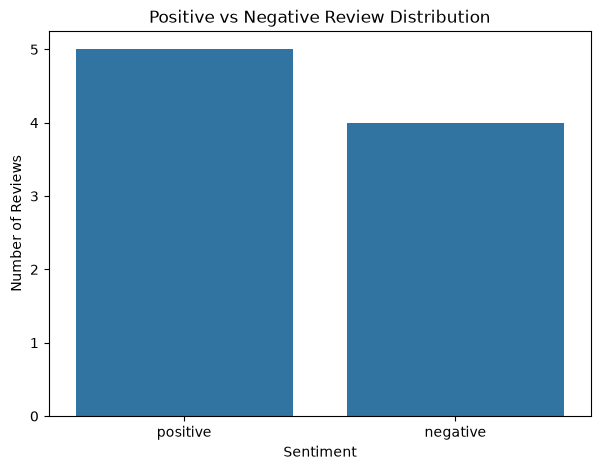

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="sentiment")

plt.title("Positive vs Negative Review Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,4.0,65.0,5.944185,60.0,60.75,63.5,67.75,73.0
positive,5.0,67.0,3.535534,63.0,65.00,66.0,69.00,72.0


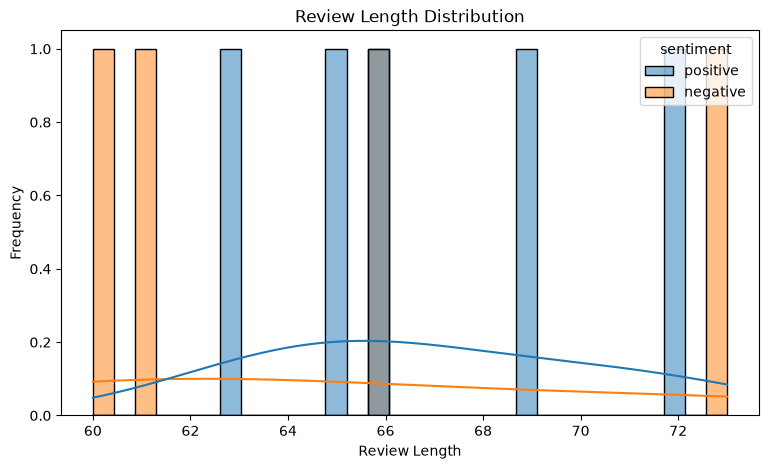

In [6]:
df["review_length"] = df["review_text"].apply(len)

display(df.groupby("sentiment")["review_length"].describe())

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="review_length",
    hue="sentiment",
    bins=30,
    kde=True
)

plt.title("Review Length Distribution")
plt.xlabel("Review Length")
plt.ylabel("Frequency")
plt.show()

In [7]:
for sentiment in ["positive", "negative"]:
    print(f"\n{sentiment.upper()} REVIEWS")

    samples = df[df["sentiment"] == sentiment]["review_text"].head(5)

    for review in samples:
        print("-", review)


POSITIVE REVIEWS
- The product quality is exceptional, exceeded all my expectations!
- Absolutely love this! Easy to setup, robust, and works flawlessly.
- Customer support helped resolve my setup question within ten minutes.
- Clean interface and intuitive controls. Highly recommended for students.
- Great value and durable build. Would definitely purchase again.

NEGATIVE REVIEWS
- Terrible customer service and the item arrived completely damaged.
- Stopped working after two days. Extremely disappointed with the purchase.
- Delivery was slow and package was missing one adapter cable.
- Not worth the money, plenty of better alternatives available.


## Data Cleaning and Exploratory Data Analysis

The dataset contains customer review text and three sentiment categories: positive, negative, and neutral.

The review_id column was removed because it does not contribute to sentiment prediction. Missing and duplicate records were handled.

Neutral reviews were excluded to create a binary sentiment classification dataset containing positive and negative reviews.

Exploratory data analysis was performed to examine sentiment distribution and review length.

In [8]:
import nltk

nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [9]:
import re
import string

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

print("NLTK preprocessing resources loaded successfully!")

NLTK preprocessing resources loaded successfully!


In [10]:
def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove numbers and special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Tokenization
    tokens = word_tokenize(text)

    # Remove stopwords and lemmatize
    cleaned_tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]

    return " ".join(cleaned_tokens)

In [11]:
df["cleaned_review"] = df["review_text"].apply(clean_text)

display(
    df[["review_text", "cleaned_review", "sentiment"]].head(10)
)

,review_text,cleaned_review,sentiment
0,"The product quality is exceptional, exceeded a...",product quality exceptional exceeded expectation,positive
1,Terrible customer service and the item arrived...,terrible customer service item arrived complet...,negative
3,"Absolutely love this! Easy to setup, robust, a...",absolutely love easy setup robust work flawlessly,positive
4,Stopped working after two days. Extremely disa...,stopped working two day extremely disappointed...,negative
5,Customer support helped resolve my setup quest...,customer support helped resolve setup question...,positive
6,Delivery was slow and package was missing one ...,delivery slow package missing one adapter cable,negative
7,Clean interface and intuitive controls. Highly...,clean interface intuitive control highly recom...,positive
8,"Not worth the money, plenty of better alternat...",worth money plenty better alternative available,negative
9,Great value and durable build. Would definitel...,great value durable build would definitely pur...,positive


In [12]:
for i in range(5):

    print("Original Review:")
    print(df["review_text"].iloc[i])

    print("\nCleaned Review:")
    print(df["cleaned_review"].iloc[i])

    print("-" * 70)

Original Review:
The product quality is exceptional, exceeded all my expectations!

Cleaned Review:
product quality exceptional exceeded expectation
----------------------------------------------------------------------
Original Review:
Terrible customer service and the item arrived completely damaged.

Cleaned Review:
terrible customer service item arrived completely damaged
----------------------------------------------------------------------
Original Review:
Absolutely love this! Easy to setup, robust, and works flawlessly.

Cleaned Review:
absolutely love easy setup robust work flawlessly
----------------------------------------------------------------------
Original Review:
Stopped working after two days. Extremely disappointed with the purchase.

Cleaned Review:
stopped working two day extremely disappointed purchase
----------------------------------------------------------------------
Original Review:
Customer support helped resolve my setup question within ten minutes.

Clean

In [13]:
empty_reviews = (df["cleaned_review"].str.strip() == "").sum()

print("Empty Reviews After Cleaning:", empty_reviews)

df = df[df["cleaned_review"].str.strip() != ""].copy()

print("Final Dataset Shape:", df.shape)

Empty Reviews After Cleaning: 0
Final Dataset Shape: (9, 4)


## Text Preprocessing and Cleaning

Text preprocessing was performed using NLTK and regular expressions.

The cleaning process included:
- Converting text to lowercase.
- Removing HTML tags and URLs.
- Removing numbers and special characters.
- Tokenizing text into individual words.
- Removing English stopwords while preserving important negation words.
- Applying WordNet lemmatization.

The cleaned reviews will be used for TF-IDF feature extraction.

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [15]:
X = df["cleaned_review"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nTraining Sentiment Distribution:")
print(y_train.value_counts())

Training Samples: 7
Testing Samples: 2

Training Sentiment Distribution:
sentiment
positive    4
negative    3
Name: count, dtype: int64


In [16]:
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=1,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

Training TF-IDF Shape: (7, 84)
Testing TF-IDF Shape: (2, 84)


In [17]:
feature_names = tfidf_vectorizer.get_feature_names_out()

print("Total Features:", len(feature_names))

print("\nFirst 30 TF-IDF Features:")
print(feature_names[:30])

Total Features: 84

First 30 TF-IDF Features:
['absolutely' 'absolutely love' 'alternative' 'alternative available'
 'arrived' 'arrived completely' 'available' 'better' 'better alternative'
 'build' 'build would' 'clean' 'clean interface' 'completely'
 'completely damaged' 'control' 'control highly' 'customer'
 'customer service' 'damaged' 'day' 'day extremely' 'definitely'
 'definitely purchase' 'disappointed' 'disappointed purchase' 'durable'
 'durable build' 'easy' 'easy setup']


In [18]:
tfidf_df = pd.DataFrame(
    X_train_tfidf.toarray(),
    columns=feature_names
)

display(tfidf_df.head())

,absolutely,absolutely love,alternative,alternative available,arrived,arrived completely,available,better,better alternative,build,...,value,value durable,work,work flawlessly,working,working two,worth,worth money,would,would definitely
0,0.00000,0.00000,0.0,0.0,0.00000,0.00000,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.0,0.0,0.000000,0.000000
1,0.00000,0.00000,0.0,0.0,0.00000,0.00000,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.00000,0.00000,0.280728,0.280728,0.0,0.0,0.000000,0.000000
2,0.27735,0.27735,0.0,0.0,0.00000,0.00000,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.27735,0.27735,0.000000,0.000000,0.0,0.0,0.000000,0.000000
3,0.00000,0.00000,0.0,0.0,0.00000,0.00000,0.0,0.0,0.0,0.280728,...,0.280728,0.280728,0.00000,0.00000,0.000000,0.000000,0.0,0.0,0.280728,0.280728
4,0.00000,0.00000,0.0,0.0,0.27735,0.27735,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.0,0.0,0.000000,0.000000


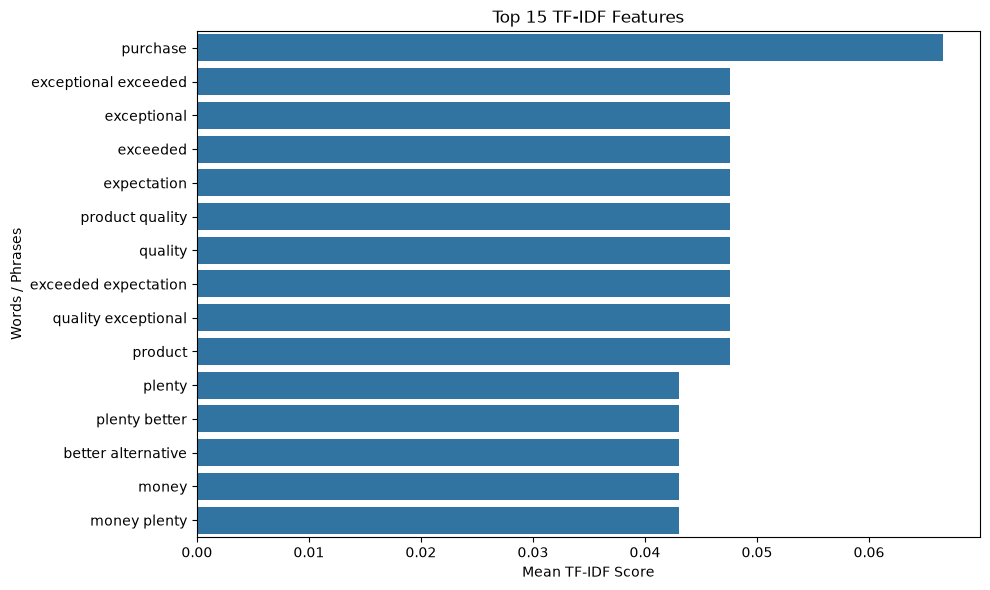

In [19]:
mean_tfidf = np.asarray(
    X_train_tfidf.mean(axis=0)
).flatten()

top_features = pd.DataFrame({
    "Feature": feature_names,
    "TF-IDF Score": mean_tfidf
}).sort_values(
    by="TF-IDF Score",
    ascending=False
).head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="TF-IDF Score",
    y="Feature"
)

plt.title("Top 15 TF-IDF Features")
plt.xlabel("Mean TF-IDF Score")
plt.ylabel("Words / Phrases")
plt.tight_layout()
plt.show()

## TF-IDF Feature Extraction

The cleaned customer reviews were transformed into numerical feature vectors using TfidfVectorizer.

The vectorizer was configured with a maximum of 5,000 features and unigram/bigram extraction.

The dataset was split into training and testing sets before fitting the vectorizer to prevent data leakage.

The resulting sparse TF-IDF matrices will be used to train sentiment classification models.

In [20]:
from sklearn.naive_bayes import MultinomialNB

In [21]:
nb_model = MultinomialNB(alpha=1.0)

nb_model.fit(X_train_tfidf, y_train)

print("Multinomial Naive Bayes training completed!")

Multinomial Naive Bayes training completed!


In [22]:
nb_predictions = nb_model.predict(X_test_tfidf)

nb_probabilities = nb_model.predict_proba(X_test_tfidf)

print("Actual Sentiments:")
print(y_test.head(10).tolist())

print("\nPredicted Sentiments:")
print(nb_predictions[:10])

Actual Sentiments:
['negative', 'positive']

Predicted Sentiments:
['positive' 'positive']


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

nb_accuracy = accuracy_score(y_test, nb_predictions)

nb_precision = precision_score(
    y_test, nb_predictions, pos_label="positive"
)

nb_recall = recall_score(
    y_test, nb_predictions, pos_label="positive"
)

nb_f1 = f1_score(
    y_test, nb_predictions, pos_label="positive"
)

print("Multinomial Naive Bayes Performance")
print("-----------------------------------")
print("Accuracy :", round(nb_accuracy, 4))
print("Precision:", round(nb_precision, 4))
print("Recall   :", round(nb_recall, 4))
print("F1 Score :", round(nb_f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, nb_predictions))

Multinomial Naive Bayes Performance
-----------------------------------
Accuracy : 0.5
Precision: 0.5
Recall   : 1.0
F1 Score : 0.6667

Classification Report:
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         1
    positive       0.50      1.00      0.67         1

    accuracy                           0.50         2
   macro avg       0.25      0.50      0.33         2
weighted avg       0.25      0.50      0.33         2



c:\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


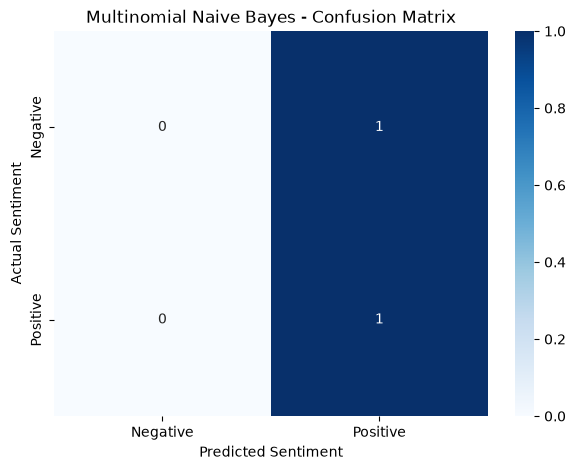

In [24]:
nb_cm = confusion_matrix(
    y_test,
    nb_predictions,
    labels=["negative", "positive"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    nb_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Multinomial Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

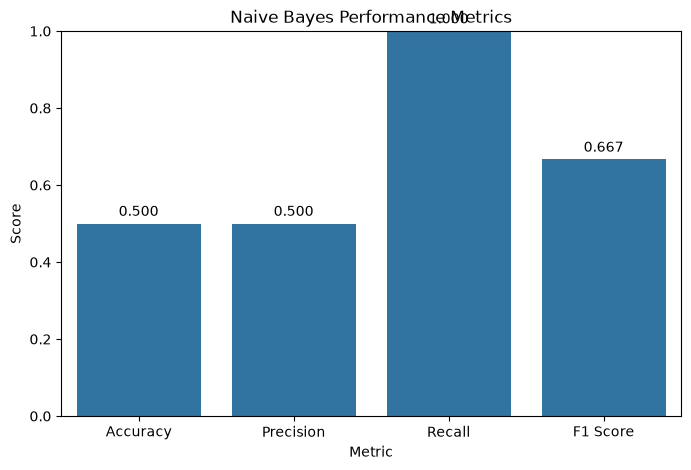

In [25]:
nb_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Score": [
        nb_accuracy,
        nb_precision,
        nb_recall,
        nb_f1
    ]
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=nb_metrics,
    x="Metric",
    y="Score"
)

plt.ylim(0, 1)
plt.title("Naive Bayes Performance Metrics")

for i, score in enumerate(nb_metrics["Score"]):
    plt.text(i, score + 0.02, f"{score:.3f}", ha="center")

plt.show()

## Multinomial Naive Bayes Classification

A Multinomial Naive Bayes classifier was trained using the TF-IDF feature matrices.

The model predicted positive and negative customer review sentiments.

Performance was evaluated using Accuracy, Precision, Recall, F1-score, and a Confusion Matrix.

In [26]:
from sklearn.linear_model import LogisticRegression

In [27]:
lr_model = LogisticRegression(
    max_iter=1000,
    C=1.0,
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [28]:
lr_predictions = lr_model.predict(X_test_tfidf)

lr_probabilities = lr_model.predict_proba(X_test_tfidf)

print("Actual Sentiments:")
print(y_test.head(10).tolist())

print("\nPredicted Sentiments:")
print(lr_predictions[:10])

Actual Sentiments:
['negative', 'positive']

Predicted Sentiments:
['positive' 'positive']


In [29]:
lr_accuracy = accuracy_score(y_test, lr_predictions)

lr_precision = precision_score(
    y_test, lr_predictions, pos_label="positive"
)

lr_recall = recall_score(
    y_test, lr_predictions, pos_label="positive"
)

lr_f1 = f1_score(
    y_test, lr_predictions, pos_label="positive"
)

print("Logistic Regression Performance")
print("--------------------------------")
print("Accuracy :", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1 Score :", round(lr_f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, lr_predictions))

Logistic Regression Performance
--------------------------------
Accuracy : 0.5
Precision: 0.5
Recall   : 1.0
F1 Score : 0.6667

Classification Report:
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         1
    positive       0.50      1.00      0.67         1

    accuracy                           0.50         2
   macro avg       0.25      0.50      0.33         2
weighted avg       0.25      0.50      0.33         2



c:\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


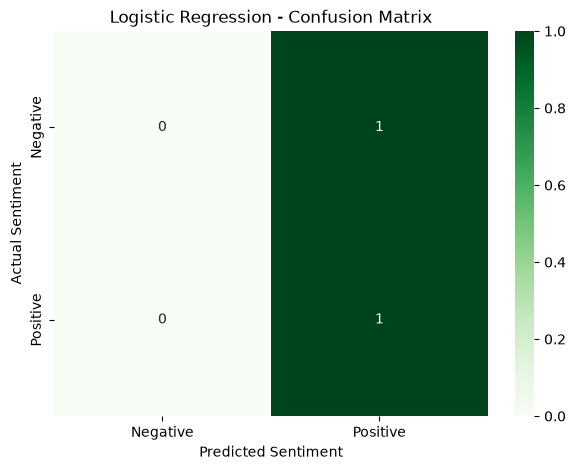

In [30]:
lr_cm = confusion_matrix(
    y_test,
    lr_predictions,
    labels=["negative", "positive"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

In [31]:
model_comparison = pd.DataFrame({
    "Model": [
        "Multinomial Naive Bayes",
        "Logistic Regression"
    ],
    "Accuracy": [
        nb_accuracy,
        lr_accuracy
    ],
    "Precision": [
        nb_precision,
        lr_precision
    ],
    "Recall": [
        nb_recall,
        lr_recall
    ],
    "F1 Score": [
        nb_f1,
        lr_f1
    ]
})

display(model_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Multinomial Naive Bayes,0.5,0.5,1.0,0.6667
1,Logistic Regression,0.5,0.5,1.0,0.6667


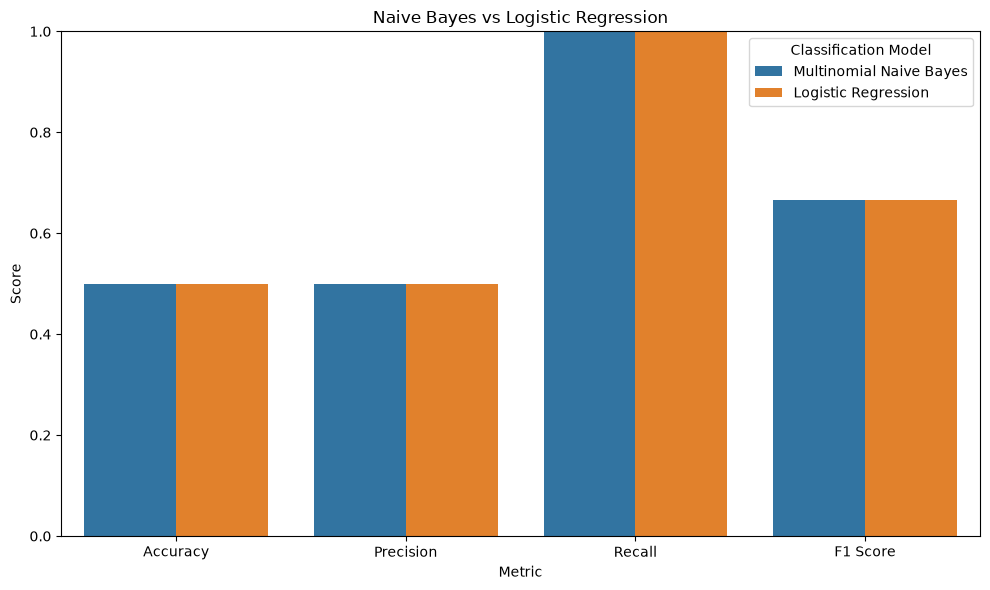

In [32]:
comparison_melted = model_comparison.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_melted,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.ylim(0, 1)
plt.title("Naive Bayes vs Logistic Regression")
plt.legend(title="Classification Model")
plt.tight_layout()
plt.show()

## Logistic Regression and Model Comparison

A Logistic Regression classifier was trained using the same TF-IDF training features.

Its performance was evaluated using Accuracy, Precision, Recall, and F1-score.

The results were compared with Multinomial Naive Bayes to identify the better-performing sentiment classification model.

In [33]:
if nb_accuracy >= lr_accuracy:
    best_model = nb_model
    best_model_name = "Multinomial Naive Bayes"
else:
    best_model = lr_model
    best_model_name = "Logistic Regression"

print("Selected Model:", best_model_name)

Selected Model: Multinomial Naive Bayes


In [34]:
def predict_sentiment(review):

    # Clean user input
    cleaned_review = clean_text(review)

    # Convert text into TF-IDF features
    review_vector = tfidf_vectorizer.transform([cleaned_review])

    # Predict sentiment
    prediction = best_model.predict(review_vector)[0]

    # Get prediction probabilities
    probabilities = best_model.predict_proba(review_vector)[0]

    # Get class probabilities
    probability_dict = dict(
        zip(best_model.classes_, probabilities)
    )

    confidence = probability_dict[prediction] * 100

    return {
        "Review": review,
        "Predicted Sentiment": prediction.upper(),
        "Confidence": f"{confidence:.2f}%"
    }

In [35]:
test_reviews = [
    "This product is absolutely amazing and works perfectly!",
    "Very disappointing quality. I regret buying this.",
    "Excellent customer service and fast delivery.",
    "The product stopped working after one day.",
    "I love this product. Highly recommended!",
    "Terrible experience. Complete waste of money."
]

for review in test_reviews:

    result = predict_sentiment(review)

    print("Review:", result["Review"])
    print("Sentiment:", result["Predicted Sentiment"])
    print("Confidence:", result["Confidence"])
    print("-" * 70)

Review: This product is absolutely amazing and works perfectly!
Sentiment: POSITIVE
Confidence: 66.31%
----------------------------------------------------------------------
Review: Very disappointing quality. I regret buying this.
Sentiment: POSITIVE
Confidence: 63.21%
----------------------------------------------------------------------
Review: Excellent customer service and fast delivery.
Sentiment: NEGATIVE
Confidence: 54.87%
----------------------------------------------------------------------
Review: The product stopped working after one day.
Sentiment: NEGATIVE
Confidence: 52.57%
----------------------------------------------------------------------
Review: I love this product. Highly recommended!
Sentiment: POSITIVE
Confidence: 68.52%
----------------------------------------------------------------------
Review: Terrible experience. Complete waste of money.
Sentiment: NEGATIVE
Confidence: 53.00%
----------------------------------------------------------------------


In [ ]:
user_review = input("Enter a customer review: ")

result = predict_sentiment(user_review)

print("\nSentiment Prediction Result")
print("=" * 40)
print("Review:", result["Review"])
print("Predicted Sentiment:", result["Predicted Sentiment"])
print("Confidence:", result["Confidence"])

In [ ]:
examples = [
    "The quality is excellent and worth every penny.",
    "I hate this product. It is completely useless.",
    "Amazing experience, I will definitely buy again.",
    "Poor quality and terrible customer support."
]

prediction_results = pd.DataFrame([
    predict_sentiment(review) for review in examples
])

display(prediction_results)

## Live Sentiment Prediction

A custom predict_sentiment() function was developed to classify user-provided customer reviews.

The function applies the same text preprocessing and TF-IDF transformation used during model training.

The selected classification model predicts positive or negative sentiment and returns its prediction confidence.

Interactive user input was also implemented to test custom review sentences.

In [ ]:
final_comparison = pd.DataFrame({
    "Model": ["Multinomial Naive Bayes", "Logistic Regression"],
    "Accuracy": [nb_accuracy, lr_accuracy],
    "Precision": [nb_precision, lr_precision],
    "Recall": [nb_recall, lr_recall],
    "F1 Score": [nb_f1, lr_f1]
})

display(final_comparison.round(4))

best_index = final_comparison["F1 Score"].idxmax()
best_model_name = final_comparison.loc[best_index, "Model"]

print("Best Performing Model:", best_model_name)

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=final_comparison,
    x="Model",
    y="Accuracy"
)

plt.ylim(0, 1)
plt.title("Sentiment Classification Accuracy Benchmark")
plt.ylabel("Accuracy")
plt.xlabel("Model")

for i, score in enumerate(final_comparison["Accuracy"]):
    plt.text(i, score + 0.02, f"{score:.4f}", ha="center")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

# Convert positive sentiment into binary labels
y_test_binary = (y_test == "positive").astype(int)

# Get positive class probabilities
nb_positive_index = list(nb_model.classes_).index("positive")
lr_positive_index = list(lr_model.classes_).index("positive")

nb_positive_probs = nb_probabilities[:, nb_positive_index]
lr_positive_probs = lr_probabilities[:, lr_positive_index]

# Calculate ROC
nb_fpr, nb_tpr, _ = roc_curve(y_test_binary, nb_positive_probs)
lr_fpr, lr_tpr, _ = roc_curve(y_test_binary, lr_positive_probs)

nb_auc = roc_auc_score(y_test_binary, nb_positive_probs)
lr_auc = roc_auc_score(y_test_binary, lr_positive_probs)

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(nb_fpr, nb_tpr, label=f"Naive Bayes (AUC = {nb_auc:.4f})")
plt.plot(lr_fpr, lr_tpr, label=f"Logistic Regression (AUC = {lr_auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

models = [
    ("Naive Bayes", nb_predictions, axes[0]),
    ("Logistic Regression", lr_predictions, axes[1])
]

for name, predictions, ax in models:

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=["negative", "positive"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=ax
    )

    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [ ]:
print("=" * 55)
print("FINAL SENTIMENT CLASSIFICATION REPORT")
print("=" * 55)

print("\nNAIVE BAYES")
print(classification_report(y_test, nb_predictions))

print("\nLOGISTIC REGRESSION")
print(classification_report(y_test, lr_predictions))

print("\nROC-AUC SCORES")
print(f"Naive Bayes: {nb_auc:.4f}")
print(f"Logistic Regression: {lr_auc:.4f}")

## Final Model Evaluation and Performance Benchmark

Both Multinomial Naive Bayes and Logistic Regression models were evaluated using the independent test dataset.

The evaluation included:
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion matrices
- ROC curve comparison

The results provide a benchmark for selecting the most suitable sentiment classification model.

In [ ]:
if nb_f1 >= lr_f1:
    best_model = nb_model
    best_model_name = "Multinomial Naive Bayes"
else:
    best_model = lr_model
    best_model_name = "Logistic Regression"

print("Selected Model:", best_model_name)
print("F1 Score:", max(nb_f1, lr_f1))

In [ ]:
def predict_sentiment(review):
    cleaned_review = clean_text(review)
    review_vector = tfidf_vectorizer.transform([cleaned_review])

    prediction = best_model.predict(review_vector)[0]
    probabilities = best_model.predict_proba(review_vector)[0]

    probability_dict = dict(zip(best_model.classes_, probabilities))
    confidence = probability_dict[prediction] * 100

    return {
        "Review": review,
        "Predicted Sentiment": prediction.upper(),
        "Confidence": f"{confidence:.2f}%"
    }

In [ ]:
import os
import joblib

os.makedirs("../results", exist_ok=True)

joblib.dump(best_model, "../results/best_sentiment_model.pkl")
joblib.dump(tfidf_vectorizer, "../results/tfidf_vectorizer.pkl")

joblib.dump({
    "model": best_model,
    "vectorizer": tfidf_vectorizer,
    "model_name": best_model_name,
    "classes": list(best_model.classes_)
}, "../results/sentiment_pipeline.pkl")

final_comparison.to_csv(
    "../results/model_comparison.csv",
    index=False
)

print("Model and results saved successfully!")

In [ ]:
print("Saved Files:")

for filename in os.listdir("../results"):
    print("-", filename)